# Embedding Matrix Changes Analysis

Compare embedding matrices before and after dual-stream training.


In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from transformers import AutoModelForCausalLM, AutoTokenizer
from model import DualStreamLLM

# Configuration
CHECKPOINT_PATH = "./checkpoints/run_20251202_085040/checkpoint-40000/model.pt"
# CHECKPOINT_PATH = "./checkpoints/run_20251107_021028/checkpoint-40000/model.pt"
MODEL_NAME = "EleutherAI/pythia-2.8b"
DEVICE = "cuda:1"


/disk/4tb/tikhonov/conda39/moe2/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
!ls ./checkpoints/run_20251202_085040/

checkpoint-40000  live_config.json  training_config.json


In [3]:

# Load original (vanilla) embeddings
vanilla_model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, torch_dtype=torch.bfloat16)
E_orig = vanilla_model.get_input_embeddings().weight.data.clone().float()
print(f"Original embeddings shape: {E_orig.shape}")

# Get original unembedding before deleting vanilla model
if hasattr(vanilla_model, 'get_output_embeddings') and vanilla_model.get_output_embeddings() is not None:
    U_orig = vanilla_model.get_output_embeddings().weight.data.clone().float()
    print(f"Original unembedding shape: {U_orig.shape}")
else:
    U_orig = None

# Load tokenizer for token analysis
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Clean up vanilla model to save memory
del vanilla_model
torch.cuda.empty_cache()

# Load trained model embeddings
checkpoint = torch.load(CHECKPOINT_PATH, map_location='cpu')
if 'model_state_dict' in checkpoint:
    state_dict = checkpoint['model_state_dict']
else:
    state_dict = checkpoint

E_trained = state_dict['emb.weight'].clone().float()
print(f"Trained embeddings shape: {E_trained.shape}")

# Get trained unembedding if available
if 'unemb.weight' in state_dict:
    U_trained = state_dict['unemb.weight'].clone().float()
    print(f"Trained unembedding shape: {U_trained.shape}")
else:
    U_trained = None


`torch_dtype` is deprecated! Use `dtype` instead!


Original embeddings shape: torch.Size([50304, 2560])
Original unembedding shape: torch.Size([50304, 2560])


/tmp/ipykernel_794391/1142366944.py:21: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(CHECKPOINT_PATH, map_location='cpu')


Trained embeddings shape: torch.Size([50304, 2560])
Trained unembedding shape: torch.Size([50304, 2560])


## 1. Global Statistics


In [4]:
# Compute difference
delta_E = E_trained - E_orig

# Norms per token
norms_orig = torch.norm(E_orig, dim=1)
norms_trained = torch.norm(E_trained, dim=1)
norms_delta = torch.norm(delta_E, dim=1)

print("=" * 60)
print("EMBEDDING NORMS")
print("=" * 60)
print(f"Original:  mean={norms_orig.mean():.4f}, std={norms_orig.std():.4f}")
print(f"Trained:   mean={norms_trained.mean():.4f}, std={norms_trained.std():.4f}")
print(f"Ratio (trained/orig): {(norms_trained / norms_orig).mean():.4f}")
print(f"\nDelta norm: mean={norms_delta.mean():.4f}, std={norms_delta.std():.4f}")
print(f"Relative delta (||delta|| / ||orig||): {(norms_delta / norms_orig).mean():.4f}")

# Global mean shift
mean_orig = E_orig.mean(dim=0)
mean_trained = E_trained.mean(dim=0)
mean_shift = mean_trained - mean_orig
print(f"\nGlobal mean shift norm: {torch.norm(mean_shift):.4f}")


EMBEDDING NORMS
Original:  mean=0.9917, std=0.0631
Trained:   mean=2.5604, std=0.3805
Ratio (trained/orig): 2.5749

Delta norm: mean=2.0915, std=0.4349
Relative delta (||delta|| / ||orig||): 2.1001

Global mean shift norm: 0.1827


## 2. Cosine Similarity with Original


COSINE SIMILARITY (orig vs trained)
Mean: 0.620695
Std:  0.092112
Min:  0.186656
Max:  1.000001


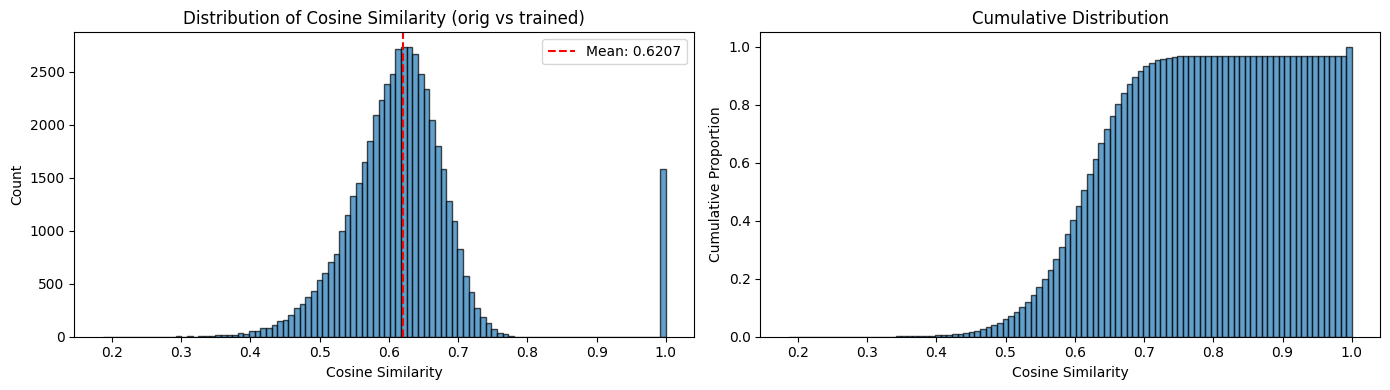

In [5]:
# Cosine similarity between original and trained embeddings (per token)
cos_sim = torch.nn.functional.cosine_similarity(E_orig, E_trained, dim=1)

print("=" * 60)
print("COSINE SIMILARITY (orig vs trained)")
print("=" * 60)
print(f"Mean: {cos_sim.mean():.6f}")
print(f"Std:  {cos_sim.std():.6f}")
print(f"Min:  {cos_sim.min():.6f}")
print(f"Max:  {cos_sim.max():.6f}")

# Histogram
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(cos_sim.numpy(), bins=100, edgecolor='black', alpha=0.7)
axes[0].set_xlabel('Cosine Similarity')
axes[0].set_ylabel('Count')
axes[0].set_title('Distribution of Cosine Similarity (orig vs trained)')
axes[0].axvline(cos_sim.mean(), color='red', linestyle='--', label=f'Mean: {cos_sim.mean():.4f}')
axes[0].legend()

# Tokens with lowest similarity (most changed)
axes[1].hist(cos_sim.numpy(), bins=100, edgecolor='black', alpha=0.7, cumulative=True, density=True)
axes[1].set_xlabel('Cosine Similarity')
axes[1].set_ylabel('Cumulative Proportion')
axes[1].set_title('Cumulative Distribution')

plt.tight_layout()
plt.show()


## 3. Low-Rank Structure of Changes (SVD)


SVD OF DELTA_E (embedding changes)
Top 10 singular values: [54.200115 44.95282  40.225937 38.718845 35.851288 34.25774  33.922943
 32.9468   32.647327 31.943853]

Variance explained by top-k components:
  Top   1: 1.28%
  Top   5: 4.08%
  Top  10: 6.47%
  Top  20: 10.27%
  Top  50: 19.02%
  Top 100: 29.03%


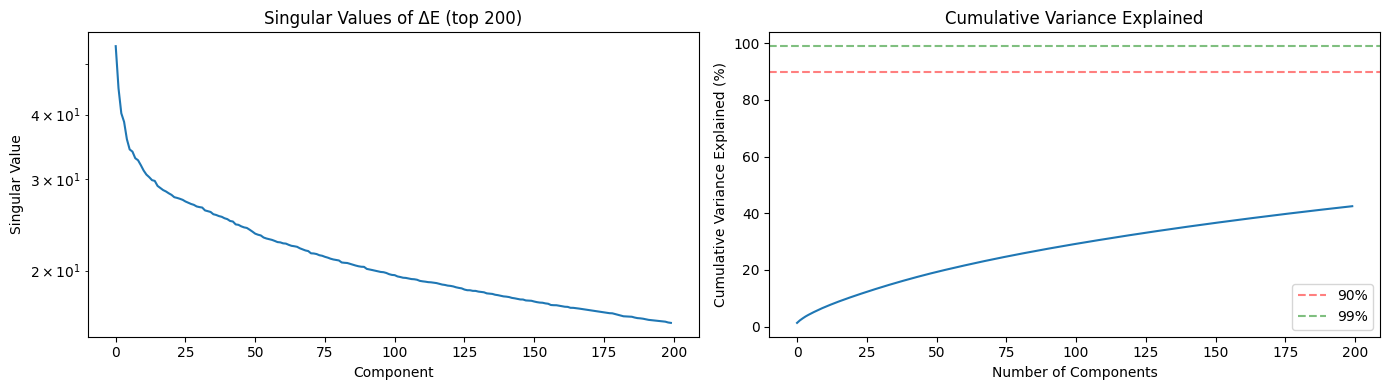

In [6]:
# SVD of the difference matrix
U, S, Vh = torch.linalg.svd(delta_E, full_matrices=False)

# Cumulative explained variance
total_var = (S ** 2).sum()
cumvar = torch.cumsum(S ** 2, dim=0) / total_var

print("=" * 60)
print("SVD OF DELTA_E (embedding changes)")
print("=" * 60)
print(f"Top 10 singular values: {S[:10].numpy()}")
print(f"\nVariance explained by top-k components:")
for k in [1, 5, 10, 20, 50, 100]:
    print(f"  Top {k:3d}: {cumvar[k-1]*100:.2f}%")

# Plot singular values
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(S[:200].numpy())
axes[0].set_xlabel('Component')
axes[0].set_ylabel('Singular Value')
axes[0].set_title('Singular Values of ΔE (top 200)')
axes[0].set_yscale('log')

axes[1].plot(cumvar[:200].numpy() * 100)
axes[1].set_xlabel('Number of Components')
axes[1].set_ylabel('Cumulative Variance Explained (%)')
axes[1].set_title('Cumulative Variance Explained')
axes[1].axhline(90, color='red', linestyle='--', alpha=0.5, label='90%')
axes[1].axhline(99, color='green', linestyle='--', alpha=0.5, label='99%')
axes[1].legend()

plt.tight_layout()
plt.show()


## 4. Most Changed Tokens


In [7]:
# Tokens with largest change (by relative delta norm)
relative_change = norms_delta / (norms_orig + 1e-8)

# Top 20 most changed
top_changed_idx = torch.argsort(relative_change, descending=True)[:20]
print("=" * 60)
print("TOP 20 MOST CHANGED TOKENS (by relative norm change)")
print("=" * 60)
for i, idx in enumerate(top_changed_idx):
    token = tokenizer.decode([idx.item()])
    print(f"{i+1:2d}. Token {idx.item():5d}: '{repr(token):20s}' | rel_change={relative_change[idx]:.4f} | cos_sim={cos_sim[idx]:.4f}")

# Top 20 least changed
bottom_changed_idx = torch.argsort(relative_change)[:20]
print("\n" + "=" * 60)
print("TOP 20 LEAST CHANGED TOKENS")
print("=" * 60)
for i, idx in enumerate(bottom_changed_idx):
    token = tokenizer.decode([idx.item()])
    print(f"{i+1:2d}. Token {idx.item():5d}: '{repr(token):20s}' | rel_change={relative_change[idx]:.4f} | cos_sim={cos_sim[idx]:.4f}")


TOP 20 MOST CHANGED TOKENS (by relative norm change)
 1. Token 16990: ''ÃÂ'                ' | rel_change=6.0882 | cos_sim=0.3641
 2. Token  7440: '' researc'          ' | rel_change=4.6852 | cos_sim=0.1867
 3. Token 21852: '' earthqu'          ' | rel_change=4.6809 | cos_sim=0.3976
 4. Token 10248: '' specim'           ' | rel_change=4.6737 | cos_sim=0.2455
 5. Token 20033: '' tradem'           ' | rel_change=4.6479 | cos_sim=0.2670
 6. Token 17030: ''ÃÂÃÂ'              ' | rel_change=4.6150 | cos_sim=0.2599
 7. Token 22394: '' cryptocur'        ' | rel_change=4.5356 | cos_sim=0.3394
 8. Token 22066: '' resemb'           ' | rel_change=4.2627 | cos_sim=0.3382
 9. Token 13236: '' teasp'            ' | rel_change=4.1006 | cos_sim=0.2700
10. Token 17505: ''gorithm'           ' | rel_change=4.0674 | cos_sim=0.3180
11. Token 22514: '' Leban'            ' | rel_change=3.9714 | cos_sim=0.3128
12. Token 14886: '' discharg'         ' | rel_change=3.9229 | cos_sim=0.3273
13. Token 10521: ''----

## 5. Norm Changes


NORM RATIO (trained / original)
Mean ratio: 2.5749
Std ratio:  0.3587
Min ratio:  1.0000
Max ratio:  6.3806

Tokens with increased norm (ratio > 1): 48721 / 50304
Tokens with decreased norm (ratio < 1): 245 / 50304


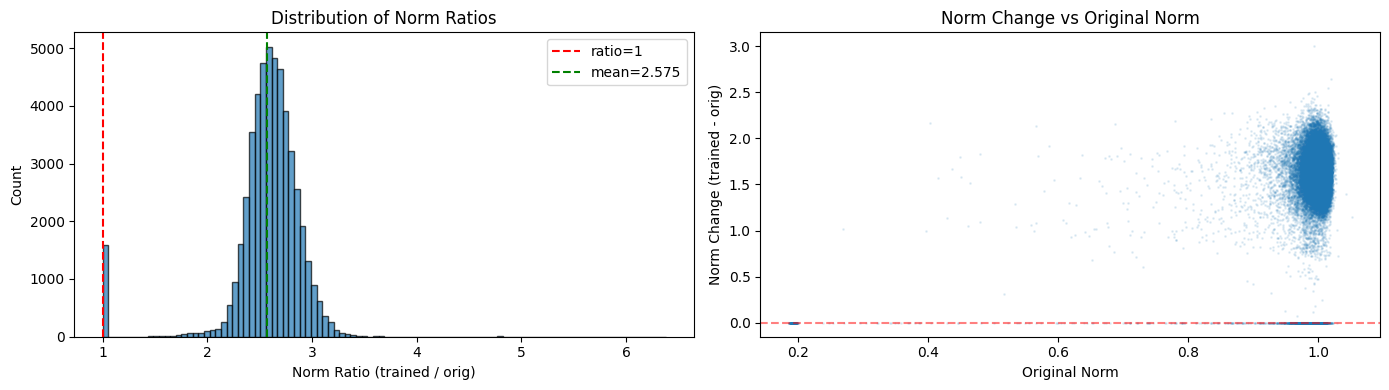

In [8]:
# Norm ratio: trained / original
norm_ratio = norms_trained / (norms_orig + 1e-8)

print("=" * 60)
print("NORM RATIO (trained / original)")
print("=" * 60)
print(f"Mean ratio: {norm_ratio.mean():.4f}")
print(f"Std ratio:  {norm_ratio.std():.4f}")
print(f"Min ratio:  {norm_ratio.min():.4f}")
print(f"Max ratio:  {norm_ratio.max():.4f}")
print(f"\nTokens with increased norm (ratio > 1): {(norm_ratio > 1).sum().item()} / {len(norm_ratio)}")
print(f"Tokens with decreased norm (ratio < 1): {(norm_ratio < 1).sum().item()} / {len(norm_ratio)}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(norm_ratio.numpy(), bins=100, edgecolor='black', alpha=0.7)
axes[0].set_xlabel('Norm Ratio (trained / orig)')
axes[0].set_ylabel('Count')
axes[0].set_title('Distribution of Norm Ratios')
axes[0].axvline(1.0, color='red', linestyle='--', label='ratio=1')
axes[0].axvline(norm_ratio.mean(), color='green', linestyle='--', label=f'mean={norm_ratio.mean():.3f}')
axes[0].legend()

# Scatter: original norm vs norm change
axes[1].scatter(norms_orig.numpy(), (norms_trained - norms_orig).numpy(), alpha=0.1, s=1)
axes[1].set_xlabel('Original Norm')
axes[1].set_ylabel('Norm Change (trained - orig)')
axes[1].set_title('Norm Change vs Original Norm')
axes[1].axhline(0, color='red', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


## 6. Unembedding Changes


In [9]:
if U_trained is not None and U_orig is not None:
    delta_U = U_trained - U_orig
    
    # Norms
    u_norms_orig = torch.norm(U_orig, dim=1)
    u_norms_trained = torch.norm(U_trained, dim=1)
    u_norms_delta = torch.norm(delta_U, dim=1)
    
    # Cosine similarity
    u_cos_sim = torch.nn.functional.cosine_similarity(U_orig, U_trained, dim=1)
    
    print("=" * 60)
    print("UNEMBEDDING ANALYSIS")
    print("=" * 60)
    print(f"Original norms:  mean={u_norms_orig.mean():.4f}, std={u_norms_orig.std():.4f}")
    print(f"Trained norms:   mean={u_norms_trained.mean():.4f}, std={u_norms_trained.std():.4f}")
    print(f"Norm ratio (trained/orig): {(u_norms_trained / u_norms_orig).mean():.4f}")
    print(f"\nCosine similarity: mean={u_cos_sim.mean():.6f}, std={u_cos_sim.std():.6f}")
    print(f"Relative delta norm: {(u_norms_delta / u_norms_orig).mean():.4f}")
    
    # SVD of unembedding delta
    U_u, S_u, Vh_u = torch.linalg.svd(delta_U, full_matrices=False)
    total_var_u = (S_u ** 2).sum()
    cumvar_u = torch.cumsum(S_u ** 2, dim=0) / total_var_u
    
    print(f"\nUnembedding SVD - variance explained:")
    for k in [1, 5, 10, 20, 50, 100]:
        print(f"  Top {k:3d}: {cumvar_u[k-1]*100:.2f}%")
else:
    print("Unembedding not available in checkpoint")


UNEMBEDDING ANALYSIS
Original norms:  mean=0.9891, std=0.1181
Trained norms:   mean=3.0823, std=0.4051
Norm ratio (trained/orig): 3.1393

Cosine similarity: mean=0.678420, std=0.082923
Relative delta norm: 2.5702

Unembedding SVD - variance explained:
  Top   1: 3.03%
  Top   5: 7.23%
  Top  10: 10.30%
  Top  20: 14.40%
  Top  50: 21.68%
  Top 100: 29.16%


## 7. Principal Components Visualization


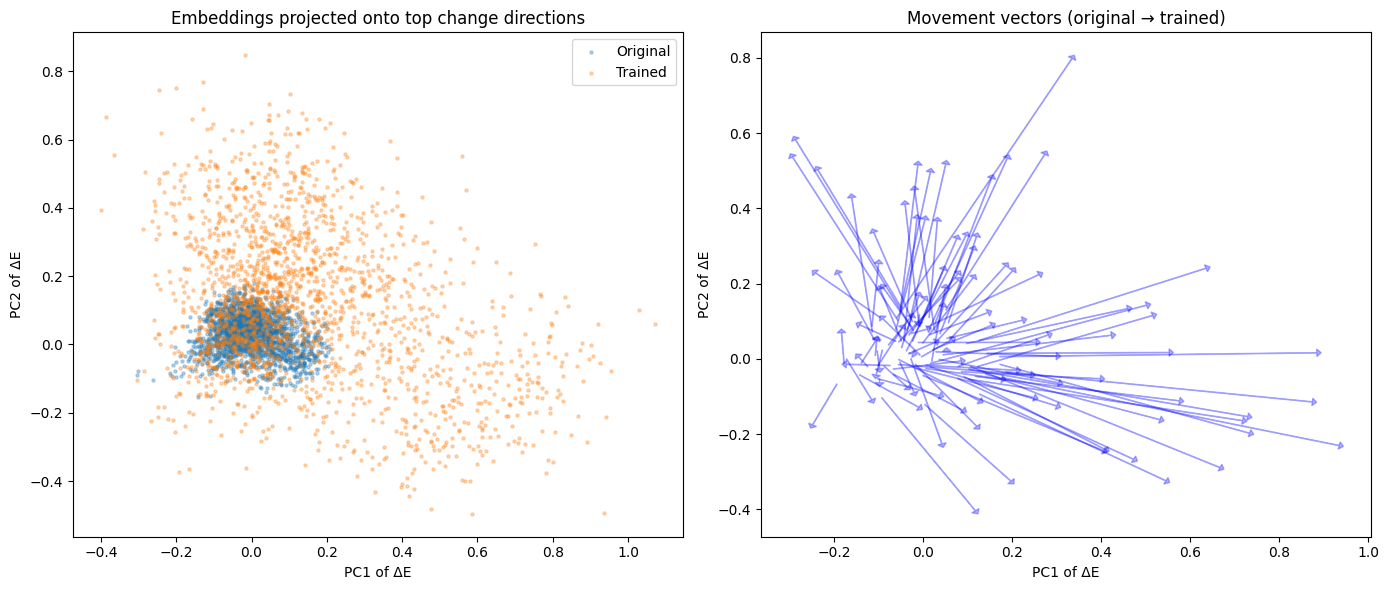

In [10]:
# Project embeddings onto top principal components of the change
# This shows which tokens moved most in the primary directions of change

# Top 2 right singular vectors (directions in embedding space)
top_directions = Vh[:2]  # [2, hidden_dim]

# Project original and trained embeddings onto these directions
proj_orig = E_orig @ top_directions.T  # [vocab, 2]
proj_trained = E_trained @ top_directions.T  # [vocab, 2]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Sample random tokens for visualization
n_sample = 2000
idx = torch.randperm(E_orig.shape[0])[:n_sample]

axes[0].scatter(proj_orig[idx, 0].numpy(), proj_orig[idx, 1].numpy(), alpha=0.3, s=5, label='Original')
axes[0].scatter(proj_trained[idx, 0].numpy(), proj_trained[idx, 1].numpy(), alpha=0.3, s=5, label='Trained')
axes[0].set_xlabel('PC1 of ΔE')
axes[0].set_ylabel('PC2 of ΔE')
axes[0].set_title('Embeddings projected onto top change directions')
axes[0].legend()

# Show movement vectors for some tokens
n_arrows = 100
arrow_idx = torch.randperm(E_orig.shape[0])[:n_arrows]
for i in arrow_idx:
    axes[1].arrow(
        proj_orig[i, 0].item(), proj_orig[i, 1].item(),
        (proj_trained[i, 0] - proj_orig[i, 0]).item(),
        (proj_trained[i, 1] - proj_orig[i, 1]).item(),
        head_width=0.02, head_length=0.01, fc='blue', ec='blue', alpha=0.3
    )
axes[1].set_xlabel('PC1 of ΔE')
axes[1].set_ylabel('PC2 of ΔE')
axes[1].set_title('Movement vectors (original → trained)')

plt.tight_layout()
plt.show()


## 8. Embedding vs Unembedding Changes Correlation


EMBEDDING vs UNEMBEDDING CHANGES
Correlation of relative changes: 0.2586
Delta alignment (cos sim): mean=0.0014, std=0.0195


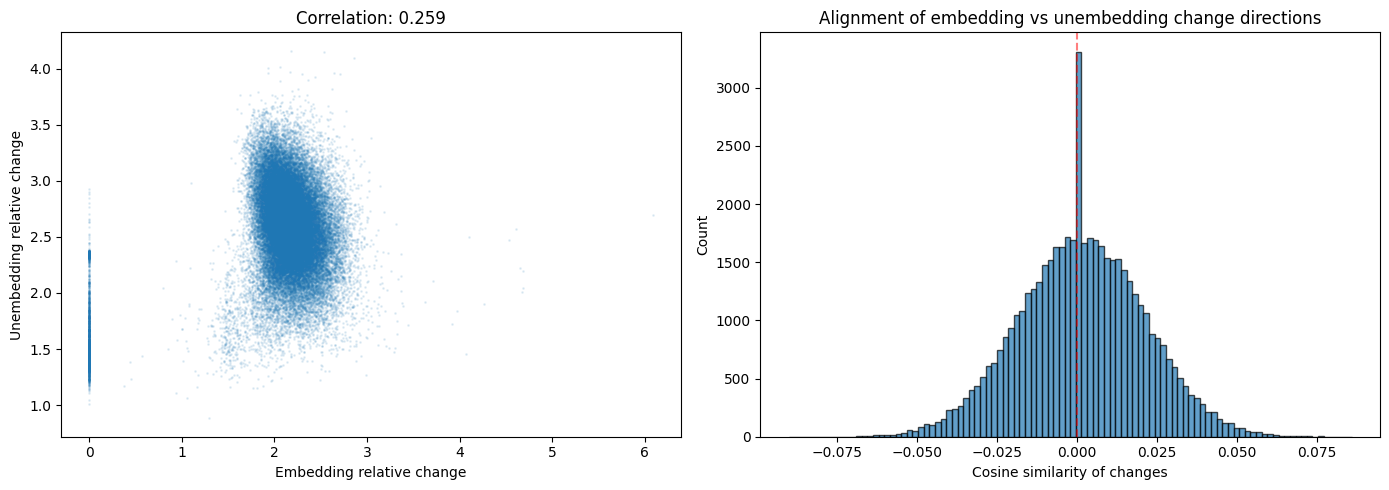

In [11]:
if U_trained is not None and U_orig is not None:
    # Correlation between embedding and unembedding changes per token
    # Do tokens that changed a lot in embedding also change a lot in unembedding?
    
    e_rel_change = norms_delta / (norms_orig + 1e-8)
    u_rel_change = u_norms_delta / (u_norms_orig + 1e-8)
    
    correlation = torch.corrcoef(torch.stack([e_rel_change, u_rel_change]))[0, 1]
    
    print("=" * 60)
    print("EMBEDDING vs UNEMBEDDING CHANGES")
    print("=" * 60)
    print(f"Correlation of relative changes: {correlation:.4f}")
    
    # Are the change directions aligned?
    # Cosine similarity between delta_E and delta_U for each token
    delta_alignment = torch.nn.functional.cosine_similarity(delta_E, delta_U, dim=1)
    print(f"Delta alignment (cos sim): mean={delta_alignment.mean():.4f}, std={delta_alignment.std():.4f}")
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    axes[0].scatter(e_rel_change.numpy(), u_rel_change.numpy(), alpha=0.1, s=1)
    axes[0].set_xlabel('Embedding relative change')
    axes[0].set_ylabel('Unembedding relative change')
    axes[0].set_title(f'Correlation: {correlation:.3f}')
    
    axes[1].hist(delta_alignment.numpy(), bins=100, edgecolor='black', alpha=0.7)
    axes[1].set_xlabel('Cosine similarity of changes')
    axes[1].set_ylabel('Count')
    axes[1].set_title('Alignment of embedding vs unembedding change directions')
    axes[1].axvline(0, color='red', linestyle='--', alpha=0.5)
    
    plt.tight_layout()
    plt.show()
else:
    print("Unembedding not available")


## Summary


In [12]:
print("=" * 60)
print("SUMMARY")
print("=" * 60)
print(f"\n1. GLOBAL CHANGES:")
print(f"   - Mean cosine similarity: {cos_sim.mean():.4f} (1.0 = no change)")
print(f"   - Mean norm ratio: {norm_ratio.mean():.4f} (1.0 = no change)")
print(f"   - Mean relative delta: {(norms_delta / norms_orig).mean():.4f}")

print(f"\n2. LOW-RANK STRUCTURE:")
print(f"   - Top 10 components explain: {cumvar[9]*100:.1f}% of variance")
print(f"   - Top 50 components explain: {cumvar[49]*100:.1f}% of variance")

print(f"\n3. INTERPRETATION:")
if norm_ratio.mean() > 1.05:
    print("   → Embeddings got LARGER (possibly compensating for averaging)")
elif norm_ratio.mean() < 0.95:
    print("   → Embeddings got SMALLER")
else:
    print("   → Embedding norms stayed similar")

if cos_sim.mean() > 0.99:
    print("   → Directions barely changed")
elif cos_sim.mean() > 0.95:
    print("   → Small directional changes")
elif cos_sim.mean() > 0.9:
    print("   → Moderate directional changes")
else:
    print("   → Significant directional changes")

if cumvar[9] > 0.9:
    print("   → Changes are VERY low-rank (top 10 explain >90%)")
elif cumvar[49] > 0.9:
    print("   → Changes are low-rank (top 50 explain >90%)")
else:
    print("   → Changes are more distributed across dimensions")


SUMMARY

1. GLOBAL CHANGES:
   - Mean cosine similarity: 0.6207 (1.0 = no change)
   - Mean norm ratio: 2.5749 (1.0 = no change)
   - Mean relative delta: 2.1001

2. LOW-RANK STRUCTURE:
   - Top 10 components explain: 6.5% of variance
   - Top 50 components explain: 19.0% of variance

3. INTERPRETATION:
   → Embeddings got LARGER (possibly compensating for averaging)
   → Significant directional changes
   → Changes are more distributed across dimensions


## 9. LayerNorm Effect: Single vs Dual Stream

Check how std differs when we have single token vs mixed tokens (before LayerNorm normalization).


STD BEFORE LAYERNORM (per token)
Single stream std: mean=0.0506, std=0.0074
Dual stream std:   mean=0.0361, std=0.0033
Ratio (dual/single): 0.7539


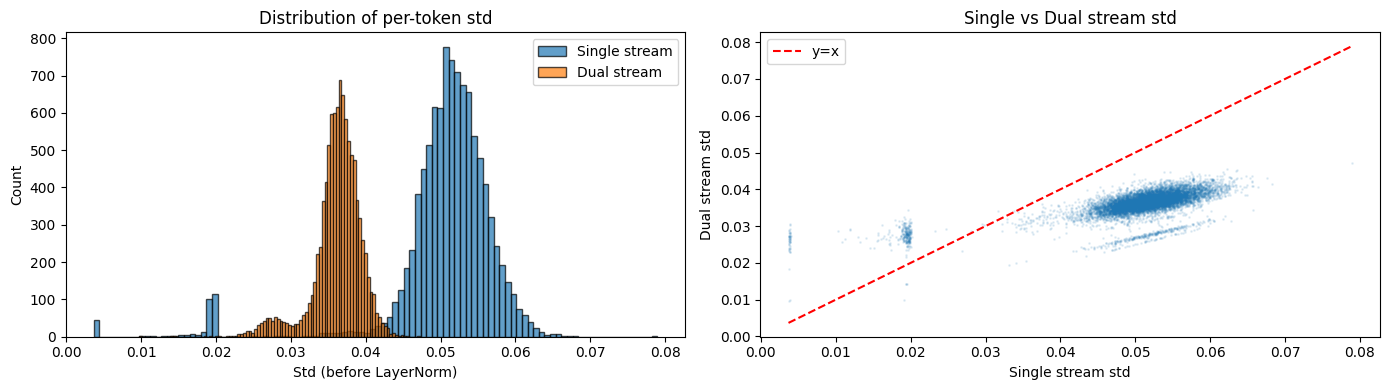

In [13]:
# Simulate LayerNorm effect on single vs dual stream
# Using TRAINED embeddings (what the model actually sees)

# Sample random pairs of tokens
n_pairs = 10000
idx_a = torch.randperm(E_trained.shape[0])[:n_pairs]
idx_b = torch.randperm(E_trained.shape[0])[:n_pairs]

# Get embeddings
emb_a = E_trained[idx_a]  # [n_pairs, hidden_dim]
emb_b = E_trained[idx_b]  # [n_pairs, hidden_dim]

# Single stream: just emb_a
single_stream = emb_a

# Dual stream: (emb_a + emb_b) / 2
dual_stream = (emb_a + emb_b) / 2

# Compute std per token (what LayerNorm would divide by)
# LayerNorm computes std over hidden_dim
single_std = single_stream.std(dim=1)  # [n_pairs]
dual_std = dual_stream.std(dim=1)      # [n_pairs]

print("=" * 60)
print("STD BEFORE LAYERNORM (per token)")
print("=" * 60)
print(f"Single stream std: mean={single_std.mean():.4f}, std={single_std.std():.4f}")
print(f"Dual stream std:   mean={dual_std.mean():.4f}, std={dual_std.std():.4f}")
print(f"Ratio (dual/single): {(dual_std / single_std).mean():.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(single_std.numpy(), bins=100, alpha=0.7, label='Single stream', edgecolor='black')
axes[0].hist(dual_std.numpy(), bins=100, alpha=0.7, label='Dual stream', edgecolor='black')
axes[0].set_xlabel('Std (before LayerNorm)')
axes[0].set_ylabel('Count')
axes[0].set_title('Distribution of per-token std')
axes[0].legend()

axes[1].scatter(single_std.numpy(), dual_std.numpy(), alpha=0.1, s=1)
axes[1].plot([single_std.min(), single_std.max()], [single_std.min(), single_std.max()], 'r--', label='y=x')
axes[1].set_xlabel('Single stream std')
axes[1].set_ylabel('Dual stream std')
axes[1].set_title('Single vs Dual stream std')
axes[1].legend()

plt.tight_layout()
plt.show()


AFTER LAYERNORM
Max absolute value per token:
  Single stream: mean=3.0664
  Dual stream:   mean=3.3000
  Ratio (single/dual): 0.9327

This means single-stream has 0.93x LARGER peak components!


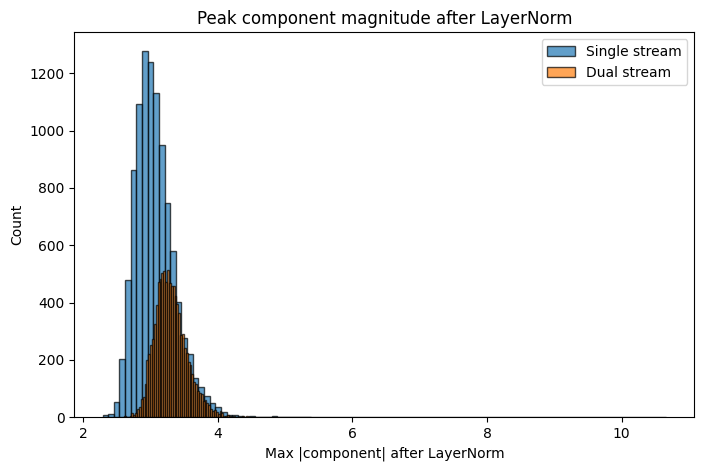

In [14]:
# Apply LayerNorm manually and compare
def manual_layernorm(x, eps=1e-5):
    """Apply LayerNorm without learnable params (gamma=1, beta=0)"""
    mean = x.mean(dim=-1, keepdim=True)
    std = x.std(dim=-1, keepdim=True)
    return (x - mean) / (std + eps)

single_ln = manual_layernorm(single_stream)
dual_ln = manual_layernorm(dual_stream)

# Compare the magnitude of components after LayerNorm
# For the same token_a, how different is the result?

# Take just emb_a and compare: 
# - single_ln: LayerNorm(emb_a)
# - What emb_a's components look like in dual_ln = LayerNorm((emb_a + emb_b) / 2)

# The contribution of emb_a in dual is emb_a/2, but after LN it's scaled differently

print("=" * 60)
print("AFTER LAYERNORM")
print("=" * 60)

# Max absolute value per token (how "peaked" is the distribution)
single_max = single_ln.abs().max(dim=1).values
dual_max = dual_ln.abs().max(dim=1).values

print(f"Max absolute value per token:")
print(f"  Single stream: mean={single_max.mean():.4f}")
print(f"  Dual stream:   mean={dual_max.mean():.4f}")
print(f"  Ratio (single/dual): {(single_max / dual_max).mean():.4f}")

# L-infinity norm (same as max abs)
print(f"\nThis means single-stream has {(single_max / dual_max).mean():.2f}x LARGER peak components!")

fig, ax = plt.subplots(1, 1, figsize=(8, 5))
ax.hist(single_max.numpy(), bins=100, alpha=0.7, label='Single stream', edgecolor='black')
ax.hist(dual_max.numpy(), bins=100, alpha=0.7, label='Dual stream', edgecolor='black')
ax.set_xlabel('Max |component| after LayerNorm')
ax.set_ylabel('Count')
ax.set_title('Peak component magnitude after LayerNorm')
ax.legend()
plt.show()


In [15]:
# Kurtosis: measure of "peakedness" of the distribution
# Higher kurtosis = more peaked, more extreme values relative to std

def kurtosis(x, dim=-1):
    """Compute kurtosis (Fisher's definition: normal = 0)"""
    mean = x.mean(dim=dim, keepdim=True)
    std = x.std(dim=dim, keepdim=True)
    z = (x - mean) / (std + 1e-8)
    return (z ** 4).mean(dim=dim) - 3  # Fisher's kurtosis

single_kurtosis = kurtosis(single_ln)
dual_kurtosis = kurtosis(dual_ln)

print("=" * 60)
print("KURTOSIS (peakedness) AFTER LAYERNORM")
print("=" * 60)
print(f"Single stream kurtosis: mean={single_kurtosis.mean():.4f}")
print(f"Dual stream kurtosis:   mean={dual_kurtosis.mean():.4f}")
print(f"\nHigher kurtosis = more peaked distribution")
print(f"Single stream is {'MORE' if single_kurtosis.mean() > dual_kurtosis.mean() else 'LESS'} peaked")

# Also look at L4/L2 ratio (another sparsity measure)
single_l4 = (single_ln ** 4).sum(dim=1) ** 0.25
single_l2 = (single_ln ** 2).sum(dim=1) ** 0.5
dual_l4 = (dual_ln ** 4).sum(dim=1) ** 0.25
dual_l2 = (dual_ln ** 2).sum(dim=1) ** 0.5

single_sparsity = single_l4 / single_l2
dual_sparsity = dual_l4 / dual_l2

print(f"\nL4/L2 ratio (sparsity measure):")
print(f"  Single stream: mean={single_sparsity.mean():.4f}")
print(f"  Dual stream:   mean={dual_sparsity.mean():.4f}")


KURTOSIS (peakedness) AFTER LAYERNORM
Single stream kurtosis: mean=-0.4629
Dual stream kurtosis:   mean=-0.2565

Higher kurtosis = more peaked distribution
Single stream is LESS peaked

L4/L2 ratio (sparsity measure):
  Single stream: mean=0.1774
  Dual stream:   mean=0.1809


In [16]:
# Compare with ORIGINAL embeddings to see if training changed this
emb_a_orig = E_orig[idx_a]
emb_b_orig = E_orig[idx_b]

single_orig = emb_a_orig
dual_orig = (emb_a_orig + emb_b_orig) / 2

single_std_orig = single_orig.std(dim=1)
dual_std_orig = dual_orig.std(dim=1)

print("=" * 60)
print("COMPARISON: ORIGINAL vs TRAINED EMBEDDINGS")
print("=" * 60)
print(f"\nOriginal embeddings:")
print(f"  Single std: mean={single_std_orig.mean():.4f}")
print(f"  Dual std:   mean={dual_std_orig.mean():.4f}")
print(f"  Ratio (dual/single): {(dual_std_orig / single_std_orig).mean():.4f}")

print(f"\nTrained embeddings:")
print(f"  Single std: mean={single_std.mean():.4f}")
print(f"  Dual std:   mean={dual_std.mean():.4f}")
print(f"  Ratio (dual/single): {(dual_std / single_std).mean():.4f}")

# After LayerNorm
single_ln_orig = manual_layernorm(single_orig)
dual_ln_orig = manual_layernorm(dual_orig)

single_max_orig = single_ln_orig.abs().max(dim=1).values
dual_max_orig = dual_ln_orig.abs().max(dim=1).values

print(f"\nMax component after LayerNorm (Original):")
print(f"  Single: {single_max_orig.mean():.4f}")
print(f"  Dual:   {dual_max_orig.mean():.4f}")
print(f"  Ratio (single/dual): {(single_max_orig / dual_max_orig).mean():.4f}")

print(f"\nMax component after LayerNorm (Trained):")
print(f"  Single: {single_max.mean():.4f}")
print(f"  Dual:   {dual_max.mean():.4f}")
print(f"  Ratio (single/dual): {(single_max / dual_max).mean():.4f}")


COMPARISON: ORIGINAL vs TRAINED EMBEDDINGS

Original embeddings:
  Single std: mean=0.0196
  Dual std:   mean=0.0139
  Ratio (dual/single): 0.7171

Trained embeddings:
  Single std: mean=0.0506
  Dual std:   mean=0.0361
  Ratio (dual/single): 0.7539

Max component after LayerNorm (Original):
  Single: 3.7194
  Dual:   3.7034
  Ratio (single/dual): 1.0101

Max component after LayerNorm (Trained):
  Single: 3.0664
  Dual:   3.3000
  Ratio (single/dual): 0.9327


## 10. Verify LayerNorm Output with Hooks

Use forward hooks to capture actual LayerNorm output from the model.


In [17]:
# Load the full model to use hooks
from transformers import AutoModelForCausalLM
import torch

model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, torch_dtype=torch.float32)
model.eval()
model = model.to('cuda')

# Storage for hook outputs
hook_outputs = {}

def make_hook(name):
    def hook(module, input, output):
        hook_outputs[name] = output.detach().cpu()
    return hook

# Register hook on first layer's input_layernorm
# Path: gpt_neox.layers[0].input_layernorm
first_ln = model.gpt_neox.layers[0].input_layernorm
hook_handle = first_ln.register_forward_hook(make_hook('first_layernorm'))

print(f"Registered hook on: {first_ln}")
print(f"LayerNorm params: weight shape={first_ln.weight.shape}, bias shape={first_ln.bias.shape}")


Registered hook on: LayerNorm((2560,), eps=1e-05, elementwise_affine=True)
LayerNorm params: weight shape=torch.Size([2560]), bias shape=torch.Size([2560])


In [18]:
# Create random token sequences and run through model
n_samples = 100
seq_len = 32

# Random token IDs
torch.manual_seed(42)
token_ids_a = torch.randint(0, 50304, (n_samples, seq_len)).to('cuda')
token_ids_b = torch.randint(0, 50304, (n_samples, seq_len)).to('cuda')

# === SINGLE STREAM ===
with torch.no_grad():
    # Run single stream (just token_ids_a)
    _ = model(token_ids_a)
    single_ln_output = hook_outputs['first_layernorm'].clone()  # [n_samples, seq_len, hidden_dim]

# === DUAL STREAM (manually mix embeddings) ===
with torch.no_grad():
    # Get embeddings
    emb_a = model.gpt_neox.embed_in(token_ids_a)  # [n_samples, seq_len, hidden_dim]
    emb_b = model.gpt_neox.embed_in(token_ids_b)
    
    # Mix embeddings
    mixed_emb = (emb_a + emb_b) / 2
    
    # Pass through first layernorm directly
    dual_ln_output = first_ln(mixed_emb).detach().cpu()

print(f"Single stream LN output shape: {single_ln_output.shape}")
print(f"Dual stream LN output shape: {dual_ln_output.shape}")


OutOfMemoryError: CUDA out of memory. Tried to allocate 616.00 MiB. GPU 0 has a total capacity of 79.26 GiB of which 365.19 MiB is free. Process 376671 has 65.88 GiB memory in use. Including non-PyTorch memory, this process has 13.01 GiB memory in use. Of the allocated memory 12.41 GiB is allocated by PyTorch, and 108.49 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://pytorch.org/docs/stable/notes/cuda.html#environment-variables)

In [ ]:
# Flatten to [n_samples * seq_len, hidden_dim]
single_flat = single_ln_output.view(-1, single_ln_output.shape[-1])
dual_flat = dual_ln_output.view(-1, dual_ln_output.shape[-1])

# Compute stats AFTER LayerNorm
# STD per token (should be ~1 after LN, but multiplied by gamma)
single_std_after = single_flat.std(dim=1)
dual_std_after = dual_flat.std(dim=1)

# L2 norm per token
single_l2_after = single_flat.norm(dim=1)
dual_l2_after = dual_flat.norm(dim=1)

# Mean per token (should be ~0 after centering, but shifted by beta)
single_mean_after = single_flat.mean(dim=1)
dual_mean_after = dual_flat.mean(dim=1)

print("=" * 70)
print("AFTER REAL LayerNorm (with gamma and beta)")
print("=" * 70)

print(f"\nSTD (per token, across hidden_dim):")
print(f"  Single stream: mean={single_std_after.mean():.4f}, std={single_std_after.std():.4f}")
print(f"  Dual stream:   mean={dual_std_after.mean():.4f}, std={dual_std_after.std():.4f}")

print(f"\nL2 NORM (per token):")
print(f"  Single stream: mean={single_l2_after.mean():.4f}, std={single_l2_after.std():.4f}")
print(f"  Dual stream:   mean={dual_l2_after.mean():.4f}, std={dual_l2_after.std():.4f}")
print(f"  Ratio (single/dual): {(single_l2_after.mean() / dual_l2_after.mean()):.4f}")

print(f"\nMEAN (per token, across hidden_dim):")
print(f"  Single stream: mean={single_mean_after.mean():.4f}, std={single_mean_after.std():.4f}")
print(f"  Dual stream:   mean={dual_mean_after.mean():.4f}, std={dual_mean_after.std():.4f}")

print(f"\nExpected L2 norm if std=1 and mean=0: sqrt({single_flat.shape[1]}) = {single_flat.shape[1]**0.5:.2f}")


In [ ]:
# Plot distributions
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# STD distribution
axes[0].hist(single_std_after.numpy(), bins=50, alpha=0.7, label='Single', edgecolor='black')
axes[0].hist(dual_std_after.numpy(), bins=50, alpha=0.7, label='Dual', edgecolor='black')
axes[0].set_xlabel('STD (per token)')
axes[0].set_ylabel('Count')
axes[0].set_title('STD after LayerNorm')
axes[0].legend()
axes[0].axvline(1.0, color='red', linestyle='--', alpha=0.5, label='std=1')

# L2 norm distribution
axes[1].hist(single_l2_after.numpy(), bins=50, alpha=0.7, label='Single', edgecolor='black')
axes[1].hist(dual_l2_after.numpy(), bins=50, alpha=0.7, label='Dual', edgecolor='black')
axes[1].set_xlabel('L2 Norm (per token)')
axes[1].set_ylabel('Count')
axes[1].set_title('L2 Norm after LayerNorm')
axes[1].legend()
axes[1].axvline(2560**0.5, color='red', linestyle='--', alpha=0.5, label=f'sqrt(d)={2560**0.5:.1f}')

# Mean distribution
axes[2].hist(single_mean_after.numpy(), bins=50, alpha=0.7, label='Single', edgecolor='black')
axes[2].hist(dual_mean_after.numpy(), bins=50, alpha=0.7, label='Dual', edgecolor='black')
axes[2].set_xlabel('Mean (per token)')
axes[2].set_ylabel('Count')
axes[2].set_title('Mean after LayerNorm')
axes[2].legend()
axes[2].axvline(0, color='red', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Cleanup
hook_handle.remove()
del model
torch.cuda.empty_cache()


In [ ]:
# vanilla_model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=torch.bfloat16)

`torch_dtype` is deprecated! Use `dtype` instead!


In [ ]:
vanilla_model

GPTNeoXForCausalLM(
  (gpt_neox): GPTNeoXModel(
    (embed_in): Embedding(50304, 2560)
    (emb_dropout): Dropout(p=0.0, inplace=False)
    (layers): ModuleList(
      (0-31): 32 x GPTNeoXLayer(
        (input_layernorm): LayerNorm((2560,), eps=1e-05, elementwise_affine=True)
        (post_attention_layernorm): LayerNorm((2560,), eps=1e-05, elementwise_affine=True)
        (post_attention_dropout): Dropout(p=0.0, inplace=False)
        (post_mlp_dropout): Dropout(p=0.0, inplace=False)
        (attention): GPTNeoXAttention(
          (query_key_value): Linear(in_features=2560, out_features=7680, bias=True)
          (dense): Linear(in_features=2560, out_features=2560, bias=True)
        )
        (mlp): GPTNeoXMLP(
          (dense_h_to_4h): Linear(in_features=2560, out_features=10240, bias=True)
          (dense_4h_to_h): Linear(in_features=10240, out_features=2560, bias=True)
          (act): GELUActivation()
        )
      )
    )
    (final_layer_norm): LayerNorm((2560,), eps=1e-05